<a href="https://colab.research.google.com/github/teju48819/phishing-url-detection-random-forest/blob/main/Phishing_URL_Detection_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
df = pd.read_csv("dataset.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())

(11055, 32)
['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']
   index  having_IPhaving_IP_Address  URLURL_Length  Shortining_Service  \
0      1                          -1              1                   1   
1      2                           1              1                   1   
2      3                           1              0                   1   
3      4                           1              0                   1   
4      5                           1              0                  -1

In [4]:
print(df.columns.tolist()[-3:])
print(df.iloc[:, -1].value_counts())
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

['Links_pointing_to_page', 'Statistical_report', 'Result']
Result
 1    6157
-1    4898
Name: count, dtype: int64
0 missing values
0 duplicate rows


Rows before removing duplicates: 11055
Rows after removing duplicates: 5849
Accuracy: 0.9418803418803419
              precision    recall  f1-score   support

          -1       0.95      0.94      0.94       604
           1       0.94      0.94      0.94       566

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



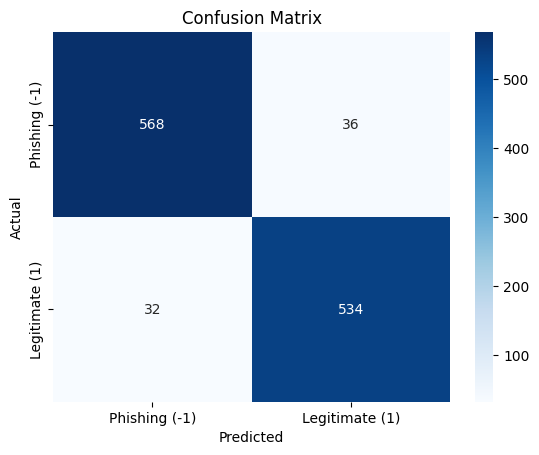

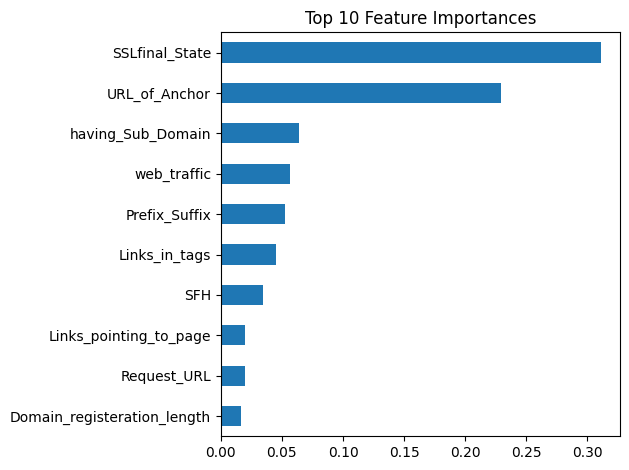

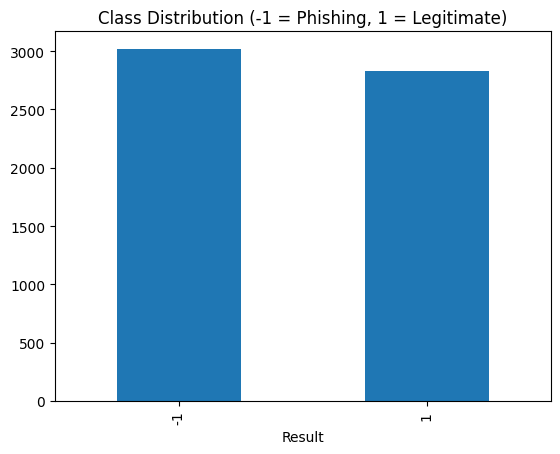

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

df = pd.read_csv("dataset.csv")
df = df.drop(columns=["index"])          # row number, not a feature
print("Rows before removing duplicates:", len(df))
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

X = df.drop(columns=["Result"])
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

# Figure 1: confusion matrix
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Phishing (-1)", "Legitimate (1)"],
            yticklabels=["Phishing (-1)", "Legitimate (1)"])
plt.title("Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

# Figure 2: top 10 feature importances
imp = pd.Series(model.feature_importances_, index=X.columns).nlargest(10)
imp.sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=200); plt.show()

# Figure 3: class distribution
y.value_counts().plot(kind="bar")
plt.title("Class Distribution (-1 = Phishing, 1 = Legitimate)")
plt.savefig("class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()